In [1]:
import openmc
import numpy as np
import math
import matplotlib.pyplot as plt
from fusion_fuel_concepts_explorer.sources import SteadyStateSource
from fusion_fuel_concepts_explorer.geometry import component_nodes as cn

import h5py

In [2]:
avg_density_Dhe3 = 1.3e20
avg_temperature_Dhe3 = 70.0
density_peaking_DHe3 = 2.5
temperature_peaking_DHe3 = 2
density_profile_DHe3 = lambda rho: avg_density_Dhe3 * density_peaking_DHe3 * ((1.0 - rho**2.0) ** (density_peaking_DHe3 - 1.0))
temperature_profile_DHe3 = lambda rho: avg_temperature_Dhe3 * temperature_peaking_DHe3 * ((1.0 - rho**2.0) ** (temperature_peaking_DHe3 - 1.0))

DHe3_source = SteadyStateSource(
    source_type="DHe3",
    volume_m3=150.0,
    n_i=density_profile_DHe3,
    T_i=temperature_profile_DHe3,
    tau_p=2.5,
)

number_of_neutrons_per_second_dhe = DHe3_source.reaction_rates_s['DT'] + DHe3_source.reaction_rates_s['DDn'] + DHe3_source.reaction_rates_s['TT'] + DHe3_source.reaction_rates_s['THe3_np']
print("D-He3: Number of neutrons per second", number_of_neutrons_per_second_dhe, '\n')
eV_to_Jouls = 1.60218e-19

# Volume (to be calculated)
tf_coil_magnet_volume = 337409.34 # * 18 if reflective BC.. TBV
tf_coil_insulation_volume = 2990501.95 # * 18
tf_coil_case_volume = 4881775.41 # * 18
ybco_volume = 0.01 * tf_coil_magnet_volume # about 1% of the total (literature), according to the definition in OpenMC it would be 0.72%

D-He3: Number of neutrons per second 1.589518216296959e+19 



In [3]:
avg_density_DT = 1.3e20
avg_temperature_DT = 14.0
density_peaking_DT = 1.168
temperature_peaking_DT = 1.83
density_profile_DT = lambda rho: avg_density_DT * density_peaking_DT * ((1.0 - rho**2.0) ** (density_peaking_DT - 1.0))
temperature_profile_DT = lambda rho: avg_temperature_DT * temperature_peaking_DT * ((1.0 - rho**2.0) ** (temperature_peaking_DT - 1.0))

DT_source = SteadyStateSource(
    source_type="DT",
    volume_m3=150.0,
    n_i=density_profile_DT,
    T_i=temperature_profile_DT,
    tau_p=2.5,
)

number_of_neutrons_per_second_dt = DT_source.reaction_rates_s['DT'] + DT_source.reaction_rates_s['DDn'] + DT_source.reaction_rates_s['TT'] + DT_source.reaction_rates_s['THe3_np']
print("D-T: Number of neutrons per second", number_of_neutrons_per_second_dt, '\n')

D-T: Number of neutrons per second 1.8508581069096337e+20 



# Flux

In [4]:
sp_dt = openmc.StatePoint("../d_t/flibe/results/statepoint.1000.h5")
sp_dhe = openmc.StatePoint("../d_he3/flibe/results/statepoint.1000.h5")
# sp_dhe_borated_water_inconel = openmc.StatePoint("../d_he3/borated_water_inconel/results/statepoint.1000.h5")
sp_dhe_water_inconel = openmc.StatePoint("../d_he3/water_inconel/results/statepoint.1000.h5")

In [5]:
def compare_flux_spectra(
    sp1, name1, volume1, number_of_neutrons_per_second1,
    sp2, name2, volume2, number_of_neutrons_per_second2,
    sp3=None, name3=None, volume3=None, number_of_neutrons_per_second3=None,
    sp4=None, name4=None, volume4=None, number_of_neutrons_per_second4=None,
    label1="Case 1", label2="Case 2", label3="Case 3", label4="Case 4",
    region_name="Region A", output_filename=None
):
    energy_bins = openmc.mgxs.GROUP_STRUCTURES["TRIPOLI-315"]
    E = np.asarray(energy_bins[:-1]) / 1e6

    def get_flux_spectrum(sp, name, volume, source_rate):
        tally = sp.get_tally(name=name)
        n_energy = len(energy_bins) - 1

        mean = np.asarray(tally.mean).reshape((-1, n_energy))
        std = np.asarray(tally.std_dev).reshape((-1, n_energy))

        flux = mean.sum(axis=0)
        flux_std = np.sqrt((std**2).sum(axis=0))

        return (
            flux / volume * source_rate,
            flux_std / volume * source_rate
        )

    def print_integrated_flux(label, flux, err):
        intervals = [
            ("Total flux", np.ones(E.shape, dtype=bool)),
            ("Flux > 7 MeV", E > 7),
            ("Flux 1–7 MeV", (E >= 1) & (E <= 7)),
            ("Flux < 1 MeV", E < 1),
        ]

        print(f"\n--- {label} ---")
        for description, mask in intervals:
            value = flux[mask].sum()
            uncertainty = np.sqrt((err[mask]**2).sum())
            print(
                f"{description:14s} = {value:.3e} "
                f"± {uncertainty:.3e} n/cm²/s"
            )

    cases = [
        (sp1, name1, volume1, number_of_neutrons_per_second1, label1),
        (sp2, name2, volume2, number_of_neutrons_per_second2, label2),
    ]

    if sp3 is not None:
        cases.append(
            (sp3, name3, volume3, number_of_neutrons_per_second3, label3)
        )

    if sp4 is not None:
        cases.append(
            (sp4, name4, volume4, number_of_neutrons_per_second4, label4)
        )

    fig, ax = plt.subplots(figsize=(8, 6))

    for sp, name, volume, source_rate, label in cases:
        flux, err = get_flux_spectrum(sp, name, volume, source_rate)

        # Ripete l'ultimo valore per disegnare anche l'ultimo bin.
        edges = np.asarray(energy_bins) / 1e6
        y = np.append(flux, flux[-1])
        uncertainty = np.append(err, err[-1])

        line, = ax.step(edges, y, where="post", label=label)
        ax.fill_between(
            edges,
            np.maximum(y - 3 * uncertainty, np.finfo(float).tiny),
            y + 3 * uncertainty,
            step="post",
            color=line.get_color(),
            alpha=0.20
        )

        print_integrated_flux(label, flux, err)

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Energy [MeV]")
    ax.set_ylabel("Flux [n/cm²/s]")
    ax.set_xlim(2e-7, 30)
    ax.set_ylim(1e-5, 1e7)
    ax.grid(alpha=0.2, which="both")
    ax.legend(loc="upper left")
    # ax.legend()
    ax.set_title(f"Flux spectrum comparison on {region_name}")

    fig.tight_layout()
    fig.savefig(output_filename or f"{region_name}.pdf", format="pdf")
    plt.show()


--- D-T (FLiBe) ---
Total flux     = 2.747e+06 ± 1.682e+05 n/cm²/s
Flux > 7 MeV   = 7.632e+03 ± 3.668e+02 n/cm²/s
Flux 1–7 MeV   = 5.812e+04 ± 2.241e+03 n/cm²/s
Flux < 1 MeV   = 2.681e+06 ± 1.681e+05 n/cm²/s

--- D-³He (FLiBe) ---
Total flux     = 5.983e+04 ± 2.510e+03 n/cm²/s
Flux > 7 MeV   = 1.092e+02 ± 1.271e+01 n/cm²/s
Flux 1–7 MeV   = 1.156e+03 ± 1.750e+02 n/cm²/s
Flux < 1 MeV   = 5.857e+04 ± 2.504e+03 n/cm²/s

--- D-³He (water-inconel) ---
Total flux     = 1.320e+04 ± 2.425e+02 n/cm²/s
Flux > 7 MeV   = 8.755e+01 ± 8.076e+00 n/cm²/s
Flux 1–7 MeV   = 7.182e+02 ± 5.105e+01 n/cm²/s
Flux < 1 MeV   = 1.240e+04 ± 2.369e+02 n/cm²/s


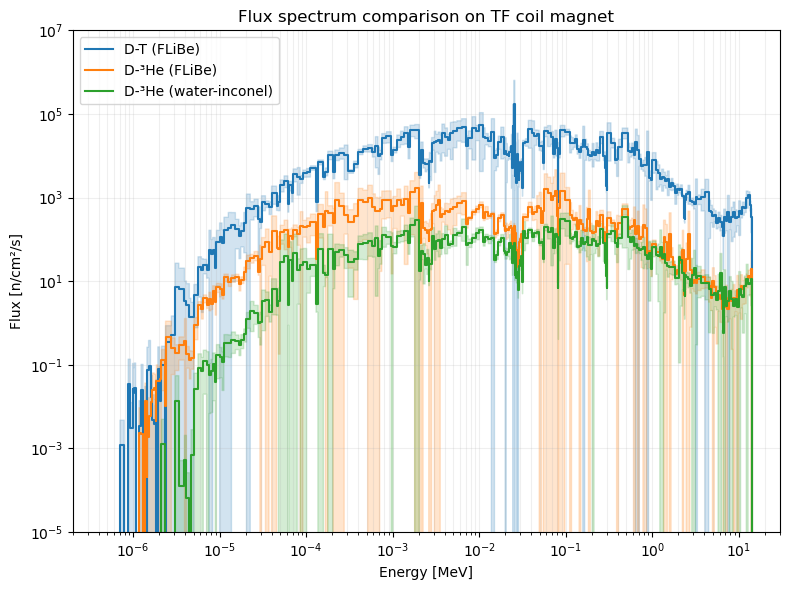

In [6]:
compare_flux_spectra(
    sp1=sp_dt,
    name1="neutron_spectra_tf_coil_magnet",
    volume1=tf_coil_magnet_volume*1e6,
    number_of_neutrons_per_second1=number_of_neutrons_per_second_dt,

    sp2=sp_dhe,
    name2="neutron_spectra_tf_coil_magnet",
    volume2=tf_coil_magnet_volume*1e6,
    number_of_neutrons_per_second2=number_of_neutrons_per_second_dhe,

    # sp3=sp_dhe_borated_water_inconel,
    sp3=sp_dhe_water_inconel,
    name3="neutron_spectra_tf_coil_magnet",
    volume3=tf_coil_magnet_volume*1e6,
    number_of_neutrons_per_second3=number_of_neutrons_per_second_dhe,

    label1="D-T (FLiBe)",
    label2="D-³He (FLiBe)",
    # label3="D-³He (borated water-inconel)",
    label3="D-³He (water-inconel)",
    region_name="TF coil magnet"
)


--- D-T (FLiBe) ---
Total flux     = 7.464e+06 ± 7.818e+05 n/cm²/s
Flux > 7 MeV   = 8.067e+04 ± 4.385e+04 n/cm²/s
Flux 1–7 MeV   = 1.177e+05 ± 1.670e+04 n/cm²/s
Flux < 1 MeV   = 7.265e+06 ± 7.804e+05 n/cm²/s

--- D-³He (FLiBe) ---
Total flux     = 9.833e+04 ± 8.615e+03 n/cm²/s
Flux > 7 MeV   = 2.996e+02 ± 6.633e+01 n/cm²/s
Flux 1–7 MeV   = 2.451e+03 ± 4.713e+02 n/cm²/s
Flux < 1 MeV   = 9.558e+04 ± 8.602e+03 n/cm²/s

--- D-³He (water-inconel) ---
Total flux     = 1.747e+04 ± 3.784e+02 n/cm²/s
Flux > 7 MeV   = 5.290e+02 ± 1.944e+02 n/cm²/s
Flux 1–7 MeV   = 1.267e+03 ± 1.334e+02 n/cm²/s
Flux < 1 MeV   = 1.568e+04 ± 2.960e+02 n/cm²/s


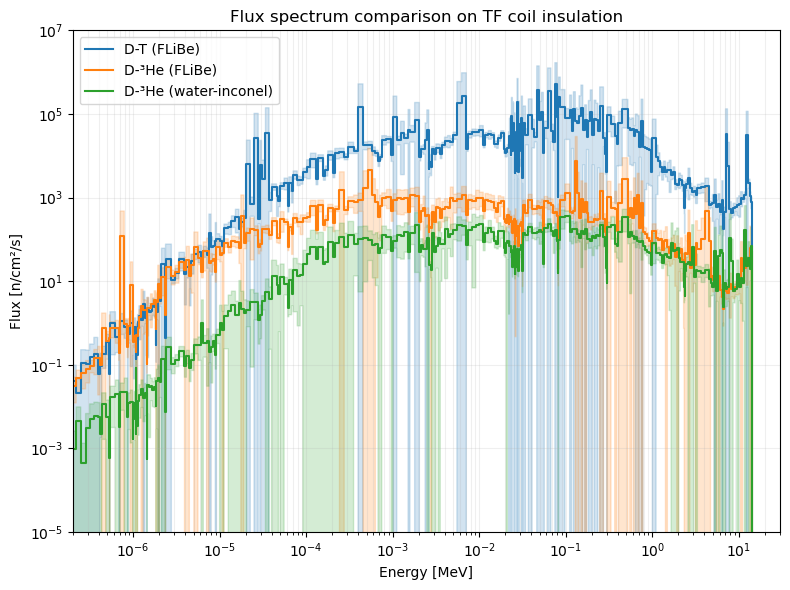

In [7]:
compare_flux_spectra(
    sp1=sp_dt,
    name1="neutron_spectra_tf_coil_insulation",
    volume1=tf_coil_insulation_volume*1e6,
    number_of_neutrons_per_second1=number_of_neutrons_per_second_dt,

    sp2=sp_dhe,
    name2="neutron_spectra_tf_coil_insulation",
    volume2=tf_coil_insulation_volume*1e6,
    number_of_neutrons_per_second2=number_of_neutrons_per_second_dhe,

    # sp3=sp_dhe_borated_water_inconel,
    sp3=sp_dhe_water_inconel,
    name3="neutron_spectra_tf_coil_insulation",
    volume3=tf_coil_insulation_volume*1e6,
    number_of_neutrons_per_second3=number_of_neutrons_per_second_dhe,

    label1="D-T (FLiBe)",
    label2="D-³He (FLiBe)",
    # label3="D-³He (borated water-inconel)",
    label3="D-³He (water-inconel)",
    region_name="TF coil insulation"
)


--- D-T (FLiBe) ---
Total flux     = 9.674e+06 ± 5.220e+05 n/cm²/s
Flux > 7 MeV   = 2.439e+05 ± 5.175e+04 n/cm²/s
Flux 1–7 MeV   = 1.034e+06 ± 2.152e+05 n/cm²/s
Flux < 1 MeV   = 8.397e+06 ± 4.727e+05 n/cm²/s

--- D-³He (FLiBe) ---
Total flux     = 2.113e+06 ± 3.565e+05 n/cm²/s
Flux > 7 MeV   = 1.909e+03 ± 4.105e+02 n/cm²/s
Flux 1–7 MeV   = 7.231e+03 ± 1.573e+03 n/cm²/s
Flux < 1 MeV   = 2.104e+06 ± 3.565e+05 n/cm²/s

--- D-³He (water-inconel) ---
Total flux     = 2.349e+04 ± 1.475e+03 n/cm²/s
Flux > 7 MeV   = 2.697e+03 ± 6.565e+02 n/cm²/s
Flux 1–7 MeV   = 5.179e+03 ± 1.204e+03 n/cm²/s
Flux < 1 MeV   = 1.562e+04 ± 5.422e+02 n/cm²/s


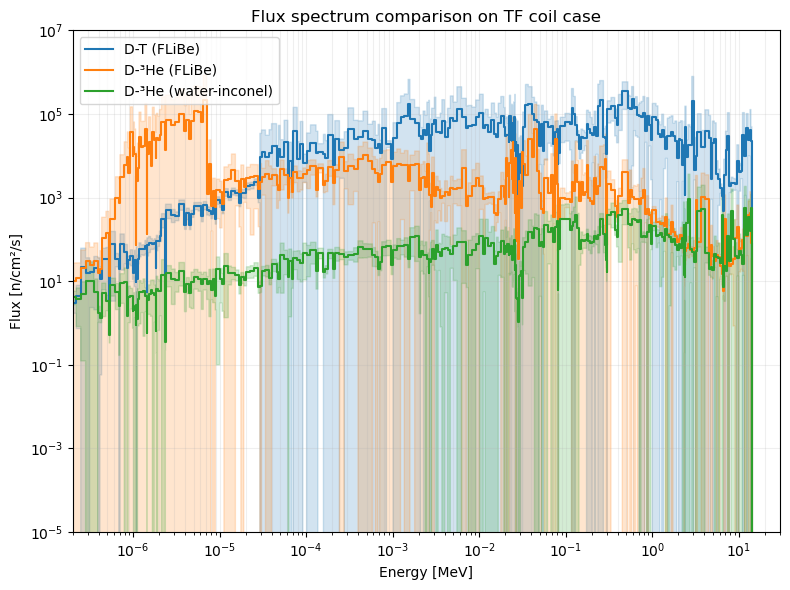

In [8]:
compare_flux_spectra(
    sp1=sp_dt,
    name1="neutron_spectra_tf_coil_case",
    volume1=tf_coil_case_volume*1e6,
    number_of_neutrons_per_second1=number_of_neutrons_per_second_dt,

    sp2=sp_dhe,
    name2="neutron_spectra_tf_coil_case",
    volume2=tf_coil_case_volume*1e6,
    number_of_neutrons_per_second2=number_of_neutrons_per_second_dhe,

    # sp3=sp_dhe_borated_water_inconel,
    sp3=sp_dhe_water_inconel,
    name3="neutron_spectra_tf_coil_case",
    volume3=tf_coil_case_volume*1e6,
    number_of_neutrons_per_second3=number_of_neutrons_per_second_dhe,

    label1="D-T (FLiBe)",
    label2="D-³He (FLiBe)",
    # label3="D-³He (borated water-inconel)",
    label3="D-³He (water-inconel)",
    region_name="TF coil case"
)